In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Image shape: (764, 860)


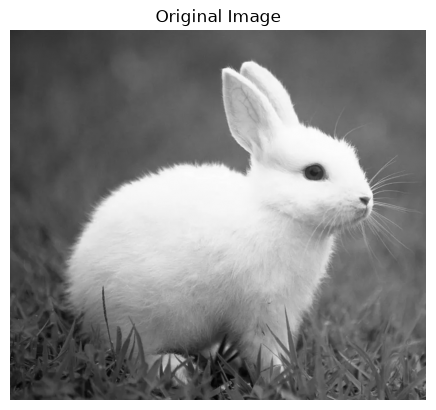

In [9]:
img = cv2.imread(
    "rabit.jpg",
    cv2.IMREAD_GRAYSCALE
)

print("Image shape:", img.shape)

plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()

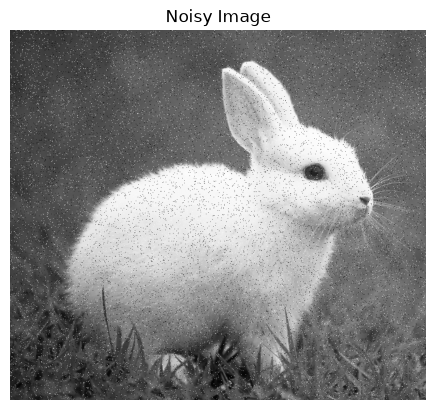

In [10]:
def add_noise(image, amount=0.04):

    noisy = image.copy()

    random = np.random.random(image.shape)

    noisy[random < amount / 2] = 0
    noisy[random > 1 - amount / 2] = 255

    return noisy


noisy_img = add_noise(img, 0.04)

plt.imshow(noisy_img, cmap="gray")
plt.title("Noisy Image")
plt.axis("off")
plt.show()

In [11]:
def mean_filter(image, kernel=3, stride=1):

    p = kernel // 2
    padded = np.pad(image, p, mode="reflect")

    h, w = image.shape

    out_h = (h - kernel) // stride + 1
    out_w = (w - kernel) // stride + 1

    result = np.zeros((out_h, out_w), dtype=np.uint8)

    for i in range(out_h):
        for j in range(out_w):

            window = padded[
                i * stride:i * stride + kernel,
                j * stride:j * stride + kernel
            ]

            result[i, j] = int(np.mean(window))

    return result

In [12]:
def median_filter(image, kernel=3, stride=1):

    p = kernel // 2
    padded = np.pad(image, p, mode="reflect")

    h, w = image.shape

    out_h = (h - kernel) // stride + 1
    out_w = (w - kernel) // stride + 1

    result = np.zeros((out_h, out_w), dtype=np.uint8)

    for i in range(out_h):
        for j in range(out_w):

            window = padded[
                i * stride:i * stride + kernel,
                j * stride:j * stride + kernel
            ]

            result[i, j] = int(np.median(window))

    return result

In [13]:
mean_img = mean_filter(noisy_img, 3, 1)

median_img = median_filter(noisy_img, 3, 1)

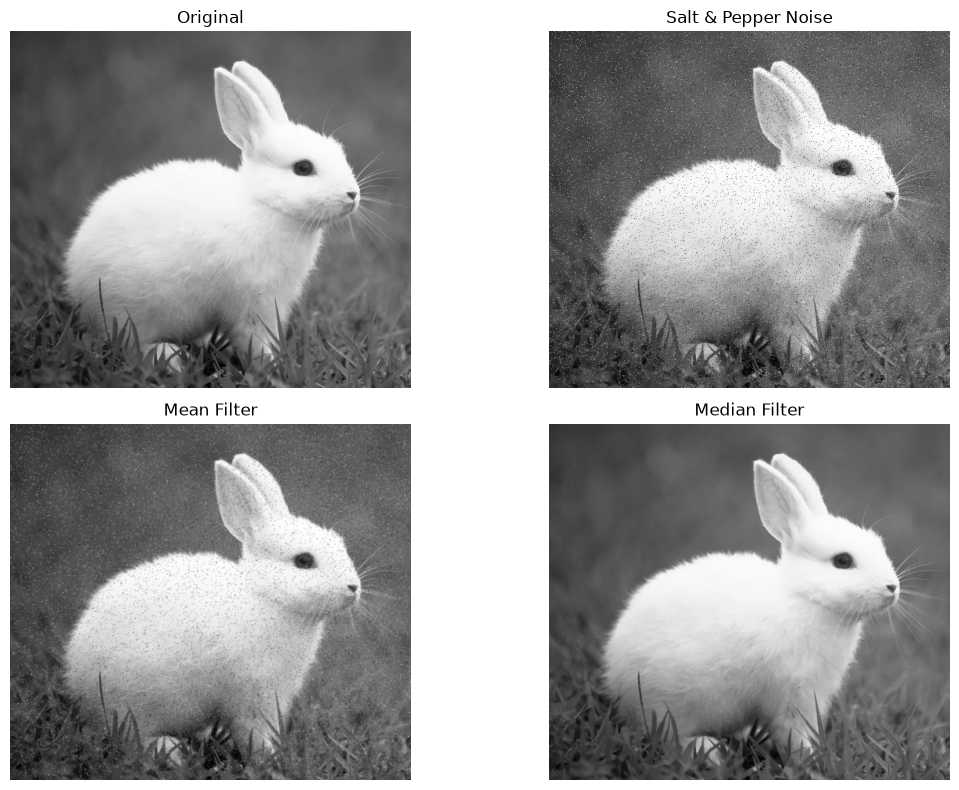

In [14]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(noisy_img, cmap="gray")
plt.title("Salt & Pepper Noise")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(mean_img, cmap="gray")
plt.title("Mean Filter")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(median_img, cmap="gray")
plt.title("Median Filter")
plt.axis("off")

plt.tight_layout()
plt.show()